# Phase 2 — Exploratory Data Analysis
**What:** understand quality, distributions, time patterns, station differences, and relationships.  
**Why:** use evidence to decide preprocessing and feature-engineering actions.  
**Output:** graphs + compact decision tables; summaries saved under `data/eda/`.  
**Decision:** every major transformation later must trace back to an EDA finding.

## 1. Load and define analysis variables

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd()
for candidate in [PROJECT_ROOT, *PROJECT_ROOT.parents]:
    if (candidate / "src" / "project_config.py").is_file():
        PROJECT_ROOT = candidate
        break
sys.path.insert(0, str(PROJECT_ROOT))
from src.project_config import *

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython import get_ipython

_ip=get_ipython()
if _ip is not None:
    _ip.run_line_magic("config", "InlineBackend.figure_formats = ['svg']")

if not CANONICAL_RAW.exists():
    raise FileNotFoundError("Run 00_dataset_integration.ipynb first.")
df=pd.read_csv(CANONICAL_RAW, parse_dates=["datetime"])
df["day_of_week"]=df["datetime"].dt.day_name()
df["season"]=df["month"].map({12:"Winter",1:"Winter",2:"Winter",3:"Spring",4:"Spring",5:"Spring",6:"Summer",7:"Summer",8:"Summer",9:"Autumn",10:"Autumn",11:"Autumn"})
NUMERIC = POLLUTANTS + WEATHER
EDA_DIR.mkdir(parents=True, exist_ok=True)
print(df.shape, df["station"].nunique())

(420768, 21) 12


## 2. Missing-value analysis
**Decision rule:** preserve variables when missingness is modest; impute predictors later using training-fitted values. Never impute the future target.

,missing,percent
CO,20701,4.920
O3,13277,3.155
NO2,12116,2.879
SO2,9021,2.144
PM2.5,8739,2.077
PM10,6449,1.533
wd,1822,0.433
DEWP,403,0.096
TEMP,398,0.095
PRES,393,0.093


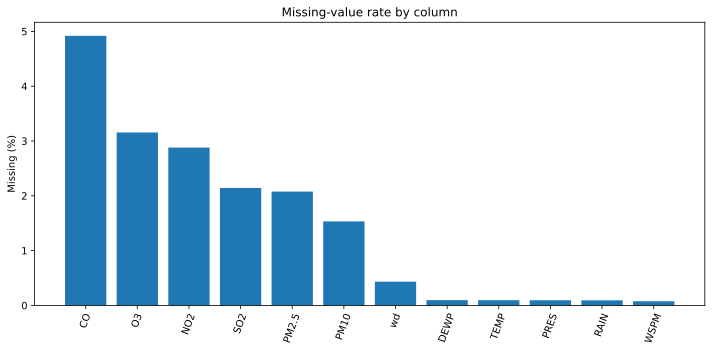

,missing,percent,decision
CO,20701,4.920,Retain; training-fitted imputation later
O3,13277,3.155,Retain; training-fitted imputation later
NO2,12116,2.879,Retain; training-fitted imputation later
SO2,9021,2.144,Retain; training-fitted imputation later
PM2.5,8739,2.077,Retain; training-fitted imputation later
PM10,6449,1.533,Retain; training-fitted imputation later
wd,1822,0.433,Retain; training-fitted imputation later
DEWP,403,0.096,Retain; training-fitted imputation later
TEMP,398,0.095,Retain; training-fitted imputation later
PRES,393,0.093,Retain; training-fitted imputation later


In [2]:
missing = pd.DataFrame({"missing":df.isna().sum()})
missing["percent"] = missing["missing"]/len(df)*100
missing=missing.sort_values("percent", ascending=False)
display(missing[missing["missing"]>0].round(3))
missing.to_csv(EDA_DIR/"phase2_missingness_summary.csv")

fig,ax=plt.subplots(figsize=(10,5))
m=missing[missing["missing"]>0]
ax.bar(m.index, m["percent"])
ax.set_ylabel("Missing (%)"); ax.set_title("Missing-value rate by column")
ax.tick_params(axis="x", rotation=70)
plt.tight_layout(); plt.show()

decision = missing[missing["missing"]>0].copy()
decision["decision"] = np.where(decision["percent"] < 5, "Retain; training-fitted imputation later", "Investigate separately")
display(decision[["missing","percent","decision"]].round(3))

## 3. Integrity and duplicate analysis

In [3]:
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Duplicate station+datetime:", int(df.duplicated(["station","datetime"]).sum()))
gap_total=0
for station,g in df.groupby("station"):
    d=g.sort_values("datetime")["datetime"].diff().dropna()
    gap_total += int((d!=pd.Timedelta(hours=1)).sum())
print("Non-hourly gaps:", gap_total)
assert df.duplicated().sum()==0
assert df.duplicated(["station","datetime"]).sum()==0
assert gap_total==0

Exact duplicate rows: 0
Duplicate station+datetime: 0
Non-hourly gaps: 0


## 4. Outlier analysis
**Method:** Tukey 1.5×IQR is a screening rule, not proof of bad data.  
**Decision:** for continuous predictors, use capping later to preserve hourly observations; do not cap the target.

In [4]:
out_rows=[]
for c in CONTINUOUS + ["RAIN"]:
    s=df[c].dropna()
    q1,q3=s.quantile(.25),s.quantile(.75)
    iqr=q3-q1
    low,high=q1-1.5*iqr,q3+1.5*iqr
    if iqr==0:
        count=int((s!=q1).sum())
        method="IQR degenerates; inspect zero-inflation"
    else:
        count=int(((s<low)|(s>high)).sum())
        method="1.5×IQR screening"
    out_rows.append([c,q1,q3,iqr,low,high,count,count/len(s)*100,method])
outlier_summary=pd.DataFrame(out_rows,columns=["variable","Q1","Q3","IQR","lower_fence","upper_fence","outlier_count","outlier_percent","method"]).set_index("variable")
display(outlier_summary.round(3))
outlier_summary.to_csv(EDA_DIR/"phase2_iqr_outlier_summary.csv")

fig,axes=plt.subplots(2,6,figsize=(16,7))
for ax,c in zip(axes.ravel(), POLLUTANTS+WEATHER):
    ax.boxplot(df[c].dropna(), vert=True)
    ax.set_title(c)
plt.tight_layout(); plt.show()

decision=outlier_summary.copy()
decision["decision"]=np.where(decision.index=="RAIN","Retain; zero-inflated rainfall needs separate handling",
                               "Retain observations; cap predictor extremes in preprocessing")
display(decision[["outlier_percent","decision"]].round(3))

,Q1,Q3,IQR,lower_fence,upper_fence,outlier_count,outlier_percent,method
variable,,,,,,,,
PM2.5,20.0,111.0,91.0,-116.50,247.50,19142,4.646,1.5×IQR screening
PM10,36.0,145.0,109.0,-127.50,308.50,14658,3.538,1.5×IQR screening
SO2,3.0,20.0,17.0,-22.50,45.50,35566,8.638,1.5×IQR screening
NO2,23.0,71.0,48.0,-49.00,143.00,7021,1.718,1.5×IQR screening
CO,500.0,1500.0,1000.0,-1000.00,3000.00,28054,7.012,1.5×IQR screening
O3,11.0,82.0,71.0,-95.50,188.50,16599,4.073,1.5×IQR screening
TEMP,3.1,23.3,20.2,-27.20,53.60,0,0.000,1.5×IQR screening
PRES,1002.3,1019.0,16.7,977.25,1044.05,0,0.000,1.5×IQR screening
DEWP,-8.9,15.1,24.0,-44.90,51.10,0,0.000,1.5×IQR screening


/var/folders/w2/kc9b50fd1wx13t124jhfyw940000gn/T/ipykernel_46348/1271564805.py:20: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[c].dropna(), vert=True)
/var/folders/w2/kc9b50fd1wx13t124jhfyw940000gn/T/ipykernel_46348/1271564805.py:20: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[c].dropna(), vert=True)
/var/folders/w2/kc9b50fd1wx13t124jhfyw940000gn/T/ipykernel_46348/1271564805.py:20: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[c].dropna(), vert=True)
/var/folders/w2/kc9b50fd1wx13t124jhfyw940000gn/T/ipykernel_46348/1271564805.py:20: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 an

,outlier_percent,decision
variable,,
PM2.5,4.646,Retain observations; cap predictor extremes in...
PM10,3.538,Retain observations; cap predictor extremes in...
SO2,8.638,Retain observations; cap predictor extremes in...
NO2,1.718,Retain observations; cap predictor extremes in...
CO,7.012,Retain observations; cap predictor extremes in...
O3,4.073,Retain observations; cap predictor extremes in...
TEMP,0.000,Retain observations; cap predictor extremes in...
PRES,0.000,Retain observations; cap predictor extremes in...
DEWP,0.000,Retain observations; cap predictor extremes in...


## 5. Distribution analysis
**Decision:** use skewness to decide whether a transformation is worth testing; do not transform merely because a histogram is non-normal.

,count,mean,median,std,min,max,skew
PM2.5,412029.0,79.793,55.0,80.822,2.000,999.0,2.014
PM10,414319.0,104.603,82.0,91.772,2.000,999.0,1.886
SO2,411747.0,15.831,7.0,21.651,0.286,500.0,3.010
NO2,408652.0,50.639,43.0,35.128,1.026,290.0,1.050
CO,400067.0,1230.766,900.0,1160.183,100.000,10000.0,2.570
O3,407491.0,57.372,45.0,56.662,0.214,1071.0,1.660
TEMP,420370.0,13.539,14.5,11.436,-19.900,41.6,-0.104
PRES,420375.0,1010.747,1010.4,10.474,982.400,1042.8,0.106
DEWP,420365.0,2.491,3.1,13.794,-43.400,29.1,-0.188
RAIN,420378.0,0.064,0.0,0.821,0.000,72.5,30.044


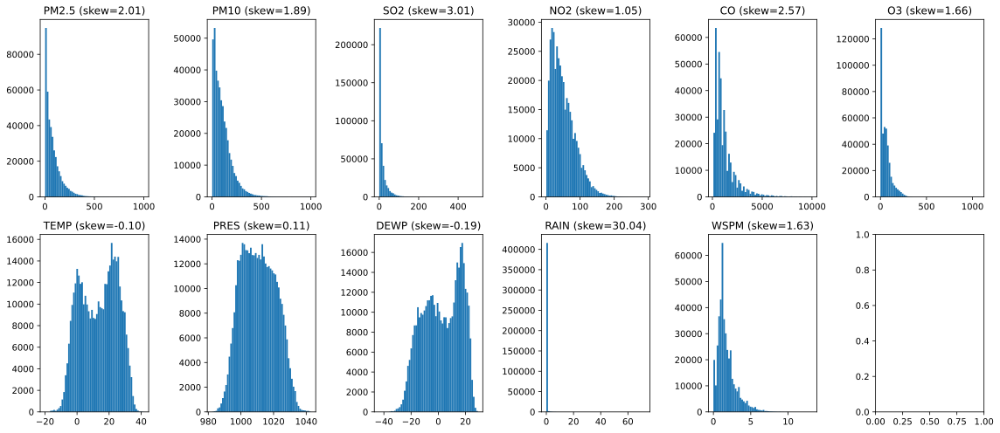

,skew,decision
PM2.5,2.014,Strong skew: consider robust/tree models; test...
PM10,1.886,Strong skew: consider robust/tree models; test...
SO2,3.010,Strong skew: consider robust/tree models; test...
NO2,1.050,Strong skew: consider robust/tree models; test...
CO,2.570,Strong skew: consider robust/tree models; test...
O3,1.660,Strong skew: consider robust/tree models; test...
TEMP,-0.104,No strong skew flag
PRES,0.106,No strong skew flag
DEWP,-0.188,No strong skew flag
RAIN,30.044,Strong skew: consider robust/tree models; test...


In [5]:
dist=df[NUMERIC].agg(["count","mean","median","std","min","max"]).T
dist["skew"]=df[NUMERIC].skew()
display(dist.round(3))
dist.to_csv(EDA_DIR/"phase2_numeric_summary.csv")

fig,axes=plt.subplots(2,6,figsize=(16,7))
for ax,c in zip(axes.ravel(), POLLUTANTS+WEATHER):
    ax.hist(df[c].dropna(), bins=60)
    ax.set_title(f"{c} (skew={df[c].skew():.2f})")
plt.tight_layout(); plt.show()

dist_dec=dist[["skew"]].copy()
dist_dec["decision"]=np.where(dist_dec["skew"].abs()>1,
                              "Strong skew: consider robust/tree models; test transformation only if needed",
                              "No strong skew flag")
display(dist_dec.round(3))

## 6. Temporal patterns
**Decision:** time structure is present if the hourly/monthly/seasonal means change. This supports temporal and cyclical features.

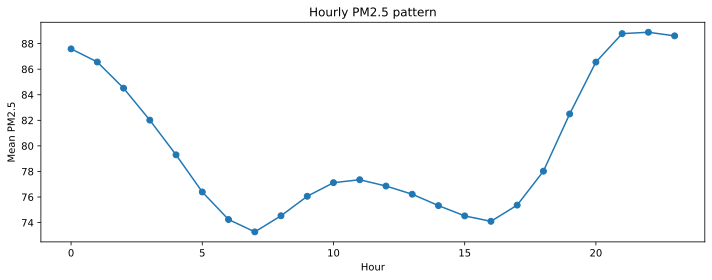

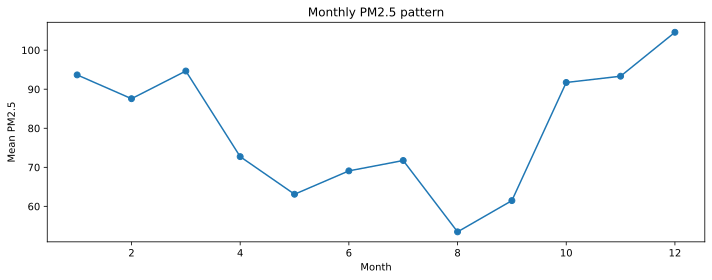

,count,mean,median
hour,,,
0,17262,87.59,62.0
1,17252,86.56,61.0
2,17248,84.52,60.0
3,17204,82.01,58.0
4,17233,79.30,57.0
5,17239,76.40,54.0
6,17256,74.24,53.0
7,17231,73.27,52.0
8,17256,74.53,53.0


,count,mean,median
season,,,
Autumn,102746,82.33,56.0
Spring,103705,76.97,58.0
Summer,103671,64.67,51.0
Winter,101907,95.48,56.0


Decision: create hour_sin/hour_cos, day_of_week, is_weekend, and season; retain month as a calendar feature.


In [6]:
hourly=df.groupby("hour")["PM2.5"].agg(["count","mean","median"])
monthly=df.groupby("month")["PM2.5"].agg(["count","mean","median"])
seasonal=df.groupby("season")["PM2.5"].agg(["count","mean","median"])

fig,ax=plt.subplots(figsize=(10,4))
ax.plot(hourly.index,hourly["mean"],marker="o")
ax.set_xlabel("Hour"); ax.set_ylabel("Mean PM2.5"); ax.set_title("Hourly PM2.5 pattern")
plt.tight_layout(); plt.show()

fig,ax=plt.subplots(figsize=(10,4))
ax.plot(monthly.index,monthly["mean"],marker="o")
ax.set_xlabel("Month"); ax.set_ylabel("Mean PM2.5"); ax.set_title("Monthly PM2.5 pattern")
plt.tight_layout(); plt.show()

display(hourly.round(2))
display(seasonal.round(2))
print("Decision: create hour_sin/hour_cos, day_of_week, is_weekend, and season; retain month as a calendar feature.")

## 7. Station analysis
**Decision:** station is contextual information, so retain it as a categorical predictor unless later experiments show no value.

,count,mean,median,std,min,max
station,,,,,,
Dongsi,34314,86.19,61.0,86.58,3.0,737.0
Wanshouxigong,34368,85.02,60.0,85.98,3.0,999.0
Nongzhanguan,34436,84.84,59.0,86.23,2.0,844.0
Gucheng,34418,83.85,60.0,82.80,2.0,770.0
Wanliu,34682,83.37,59.0,81.91,2.0,957.0
Guanyuan,34448,82.93,59.0,80.93,2.0,680.0
Aotizhongxin,34139,82.77,58.0,82.14,3.0,898.0
Tiantan,34387,82.16,59.0,80.92,3.0,821.0
Shunyi,34151,79.49,55.0,81.23,2.0,941.0


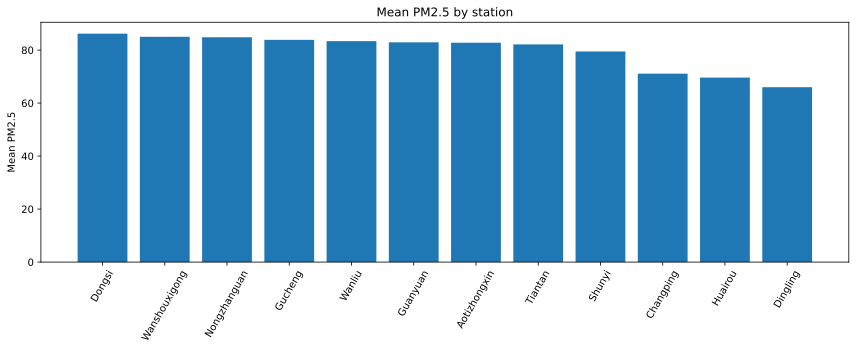

Decision: keep station as a categorical feature so the model can learn persistent site-level differences.


In [7]:
station_summary=df.groupby("station")["PM2.5"].agg(["count","mean","median","std","min","max"]).sort_values("mean",ascending=False)
display(station_summary.round(2))
station_summary.to_csv(EDA_DIR/"phase2_station_pm25_summary.csv")

fig,ax=plt.subplots(figsize=(12,5))
ax.bar(station_summary.index,station_summary["mean"])
ax.set_ylabel("Mean PM2.5"); ax.set_title("Mean PM2.5 by station")
ax.tick_params(axis="x",rotation=60)
plt.tight_layout(); plt.show()

print("Decision: keep station as a categorical feature so the model can learn persistent site-level differences.")

## 8. Correlation and redundancy analysis
**Decision:** use the numeric values to screen relationships, but do not delete a variable only because it is correlated. Multicollinearity matters most for linear-type models and should be checked with model experiments.

Pearson correlation matrix:


,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
PM2.5,1.000,0.884,0.482,0.667,0.790,-0.150,-0.131,0.019,0.115,-0.014,-0.272
PM10,0.884,1.000,0.463,0.652,0.702,-0.111,-0.096,-0.018,0.070,-0.027,-0.184
SO2,0.482,0.463,1.000,0.499,0.536,-0.165,-0.322,0.223,-0.267,-0.040,-0.109
NO2,0.667,0.652,0.499,1.000,0.705,-0.472,-0.278,0.174,-0.032,-0.044,-0.400
CO,0.790,0.702,0.536,0.705,1.000,-0.313,-0.326,0.188,-0.057,-0.013,-0.298
O3,-0.150,-0.111,-0.165,-0.472,-0.313,1.000,0.595,-0.446,0.312,0.023,0.296
TEMP,-0.131,-0.096,-0.322,-0.278,-0.326,0.595,1.000,-0.813,0.820,0.038,0.033
PRES,0.019,-0.018,0.223,0.174,0.188,-0.446,-0.813,1.000,-0.750,-0.061,0.065
DEWP,0.115,0.070,-0.267,-0.032,-0.057,0.312,0.820,-0.750,1.000,0.086,-0.297
RAIN,-0.014,-0.027,-0.040,-0.044,-0.013,0.023,0.038,-0.061,0.086,1.000,0.021


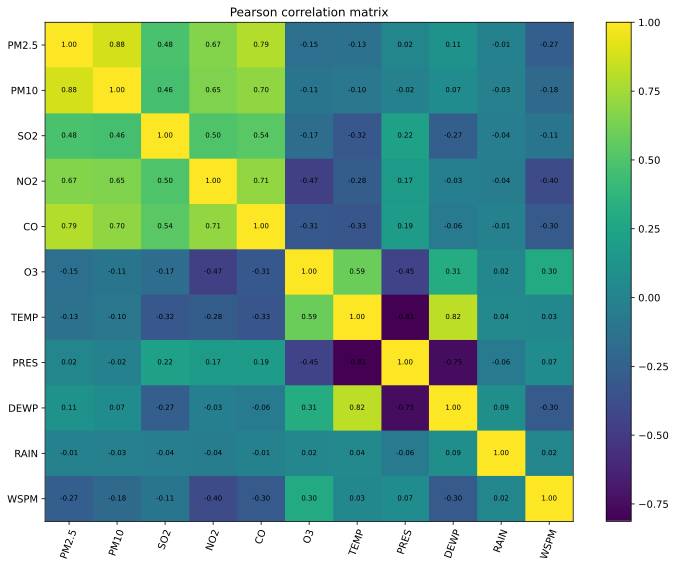

,pearson_r,abs_r,decision
PM10,0.884,0.884,Strong/moderate candidate for further modellin...
CO,0.790,0.790,Strong/moderate candidate for further modellin...
NO2,0.667,0.667,Strong/moderate candidate for further modellin...
SO2,0.482,0.482,Weaker linear relationship; keep initially and...
WSPM,-0.272,0.272,Weaker linear relationship; keep initially and...
O3,-0.150,0.150,Weaker linear relationship; keep initially and...
TEMP,-0.131,0.131,Weaker linear relationship; keep initially and...
DEWP,0.115,0.115,Weaker linear relationship; keep initially and...
PRES,0.019,0.019,Weaker linear relationship; keep initially and...
RAIN,-0.014,0.014,Weaker linear relationship; keep initially and...


Potential redundancy pairs (|r| >= 0.80):


,feature_a,feature_b,abs_r
1,TEMP,DEWP,0.820
0,TEMP,PRES,0.813


In [8]:
corr=df[NUMERIC].corr()
print("Pearson correlation matrix:")
display(corr.round(3))

fig,ax=plt.subplots(figsize=(10,8))
im=ax.imshow(corr.values,aspect="auto")
ax.set_xticks(range(len(corr.columns))); ax.set_xticklabels(corr.columns,rotation=70)
ax.set_yticks(range(len(corr.columns))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j,i,f"{corr.iloc[i,j]:.2f}",ha="center",va="center",fontsize=7)
ax.set_title("Pearson correlation matrix")
plt.colorbar(im,ax=ax); plt.tight_layout(); plt.show()
corr.to_csv(EDA_DIR/"phase2_correlation_matrix.csv")

pm25_corr=corr["PM2.5"].drop("PM2.5").sort_values(key=lambda s:s.abs(),ascending=False)
pm25_table=pm25_corr.rename("pearson_r").to_frame()
pm25_table["abs_r"]=pm25_table["pearson_r"].abs()
pm25_table["decision"]=np.where(pm25_table["abs_r"]>=0.5,"Strong/moderate candidate for further modelling checks",
                                "Weaker linear relationship; keep initially and let model experiments decide")
display(pm25_table.round(3))

pred_corr=df[NUMERIC].drop(columns=["PM2.5"]).corr().abs()
pairs=[]
for i,a in enumerate(pred_corr.columns):
    for b in pred_corr.columns[i+1:]:
        r=pred_corr.loc[a,b]
        if r>=0.80: pairs.append([a,b,r])
redundancy=pd.DataFrame(pairs,columns=["feature_a","feature_b","abs_r"]).sort_values("abs_r",ascending=False)
print("Potential redundancy pairs (|r| >= 0.80):")
display(redundancy.round(3))

## 9. Leakage check
**Decision:** only information available at the prediction time may become a predictor. `target_PM25` is future information and is never used as an input.

In [9]:
leakage_table=pd.DataFrame([
    ["No","Identifier","Drop before modelling"],
    ["target_PM25","Future value at t+1","Target only; never predictor"],
    ["target_datetime","Future timestamp","Audit/splitting only"],
    ["has_next_hour","Target availability flag","Audit/splitting only"],
    ["datetime","Prediction-time timestamp","Transform into time features; do not use future timestamps"],
    ["PM2.5 and other measurements","Observed at or before t","Potential predictors"],
],columns=["column","role","decision"])
display(leakage_table)

,column,role,decision
0,No,Identifier,Drop before modelling
1,target_PM25,Future value at t+1,Target only; never predictor
2,target_datetime,Future timestamp,Audit/splitting only
3,has_next_hour,Target availability flag,Audit/splitting only
4,datetime,Prediction-time timestamp,Transform into time features; do not use futur...
5,PM2.5 and other measurements,Observed at or before t,Potential predictors


## EDA decision summary
**Output-to-decision chain:** missingness → imputation strategy; IQR screening → outlier treatment; distributions → transformation/model consideration; temporal patterns → time/lag/rolling features; station differences → station feature; correlation → redundancy screening; leakage → feature exclusions.